# Lecture 5 — Deep Q-Networks

**Reinforcement Learning, 2025-26**

## Where we are

In the first two lectures you built tabular reinforcement learning: the action-value function $Q(s, a)$ held in a table, one entry per state-action pair, learned by Q-learning, SARSA, and Monte Carlo on a small grid world. Lecture 3 gave up the table. On a continuous-state environment there is no table to index, so we replaced exact storage with a parametric approximation $\hat{q}(s, a, \mathbf{w})$ — in the simplest case linear, $\hat{q}(s, a, \mathbf{w}) = \mathbf{w}_a^\top \mathbf{x}(s)$, evaluated on a feature map $\mathbf{x}(s)$ that we designed by hand with tile coding or radial basis functions. Lecture 4 moved from prediction to control and met the cost of approximation: the *deadly triad*. Bootstrapping, off-policy learning, and function approximation are each safe in isolation, but together they can drive the weights to diverge — a failure we isolated on Baird's counterexample, an MDP constructed for no other purpose than to trigger it.

This lecture takes the step the field took next: keep the idea of a parametric action-value function, but let the approximator be a neural network instead of a linear map on hand-built features. The result is the **Deep Q-Network**, or DQN — the algorithm that in 2015 learned to play dozens of Atari games from raw pixels at human level, and with it turned deep reinforcement learning into a field.

A neural network does not repeal the difficulties of Lecture 4. Used **naively inside Q-learning** it is, if anything, **less stable than the linear approximator**, and for reasons we can state precisely. DQN is not a new learning rule: it is **Q-learning with a neural network**, plus **two specific pieces of engineering whose only job is to control that instability**. This lecture is about those two pieces — what breaks without them, why each one works, and what the assembled algorithm can do once they are in place.

> See *Mnih, Volodymyr, et al. "Human-level control through deep reinforcement learning." nature 518.7540 (2015): 529-533*.

> *Mnih, Volodymyr, et al. "Asynchronous methods for deep reinforcement learning." International conference on machine learning. PmLR, 2016*.

## What you will learn today

By the end of this lecture you will be able to:

1. Explain why replacing a hand-crafted feature map with a neural network changes the nature of the modelling work itself — *feature engineering* becomes *representation learning* — and why that shift turns input normalization from a detail into a necessity.
2. Name and diagnose the two instabilities of naive neural Q-learning: the *correlation* of consecutive training updates, and the *moving target* produced when a bootstrapped update depends on the very parameters it is updating.
3. Explain the two components that define DQN — an *experience replay buffer* and a *target network* — and say which instability each one removes.
4. Implement a complete DQN agent, apply it to a continuous-state control problem, and read its learning curves and weight- and gradient-norm diagnostics well enough to tell healthy training from failing training.

The version of DQN built here is the 2015 algorithm in its essential form. The refinements that followed — Double DQN and Dueling architectures — are treated briefly at the end, at the level of the specific weakness each one corrects. The lecture, and the course, then close by looking past value-based methods entirely, towards the policy-gradient family.

## How we will get there

The lecture is in two parts. **Part 1** isolates the two problems before assembling anything. Each instability is studied in the smallest setting that still exhibits it, through two short demonstrations that run inline in this notebook. The first is a pure supervised-learning experiment — a small network fitting a fixed function — and shows what goes wrong when training data arrives as a correlated stream instead of as independent samples. The second is a minimal control setup and shows what goes wrong when the target of a bootstrapped update is not held fixed. Each demonstration closes by naming the remedy it motivates.

**Part 2** assembles the algorithm. We first design a new environment — a continuous-state microbe world, with a richer state and a harder task than anything in Lectures 1-4 — and then build the full agent: a Q-network, an experience replay buffer, and a target network, combined into a single DQN. We train it on the new environment, follow its diagnostics as it learns, and animate the resulting behaviour. Where the comparison is informative we set DQN against the linear agent of Lectures 3-4, whose hand-crafted features do not scale to the new problem.

The two demonstrations of Part 1 are self-contained and need nothing beyond this notebook. The Part 2 agent lives in `rlc/agents/dqn.py` and the new environment in `rlc/envs/realistic_microbe.py`; training and evaluation use `rlc/utils/training.py`, unchanged from earlier lectures.

## A network learns its own features

In Lectures 3 and 4 the approximator was linear, and everything that mattered about it lived in the feature map $\mathbf{x}(s)$. Tile coding and radial basis functions were not incidental detail: choosing the map — its resolution, its centres, its widths — *was* the modelling work, and a linear weight vector could only ever be as good as the features handed to it. A neural network removes that step. It takes the state $s$ directly as input; its hidden layers compute an internal representation of it, and only the final layer is linear, producing one value per action from that representation. What tile coding and RBFs did by hand — turn a raw state into features in which value is approximately linear — the hidden layers now do by gradient descent, learning the representation and the values that read it together. This is the substance of the word *deep*: feature engineering becomes **representation learning**, and the quality of the features stops being a fixed input to the problem and becomes part of what is optimised.

That convenience carries one obligation. A hand-crafted feature map also controlled scale, if only as a side effect: a tile-coding vector is binary, an RBF vector lies in $[0, 1]$, so whatever the units of the raw state, the features reaching the weights were already in a bounded, comparable range. Remove the map and the raw state is itself the input to the first layer — and a raw state need not be well-scaled. One coordinate may range over $[0, 12]$ and another over $[-1, 1]$; a network reading them directly lets the larger-magnitude coordinate dominate the first linear layer for no reason other than its units, and gradient descent, with a single step size shared across all inputs, copes badly when those inputs differ in scale by an order of magnitude. The remedy is routine and applied once, at the boundary between environment and agent: **each coordinate of the state is rescaled to a common fixed range**, using the bounds the environment already declares. That rescaling is the job of a thin observation wrapper, `NormalizeObs`, which we look at next.

In [1]:
from rlc.envs.wrappers import NormalizeObs
from rlc.envs.continuous_microbe import ContinuousMicrobeEnv
import numpy as np 

In [2]:
env = NormalizeObs(ContinuousMicrobeEnv())
for s in [(0., 0.), (6., 3.), (12., 6.)]: 
    print(s, "->", env.observation(np.array(s, dtype=np.float32)))

(0.0, 0.0) -> [0. 0.]
(6.0, 3.0) -> [0.5 0.5]
(12.0, 6.0) -> [1. 1.]


## The correlation problem

The previous section's upgrade came cheaply: representation learning in exchange for a normalized input. The real cost of moving to a neural network is still unpaid. Q-learning with a network, written down naively — the Lecture 4 update rule with the linear approximator replaced by a network — is unstable. The instability is not mysterious, and it is not a single fault: naive neural Q-learning fails for two specific, separable reasons, and Part 1 takes them one at a time. This section is the first.

Consider where a reinforcement learning agent's training data comes from. The agent generates it by acting: it follows a trajectory through the environment, and the transitions it learns from arrive in the order they are experienced. Consequences:
- **Consecutive transitions concern neighbouring states reached by similar actions — they are strongly correlated, the opposite of *independent***. This collides with an assumption built into the optimiser of every neural network. **Stochastic gradient descent is justified by treating each minibatch as an independent sample of the data distribution**; its stability leans on that sample being representative of the whole, not a narrow slice of one region.

Why does this matter so much for a network, when it troubled the tabular methods of Lectures 1-2 so little? 

**Because a network is a single global function: one set of parameters**, shared across every input, so an update made for one state shifts the predicted values everywhere. Train it on a correlated stream and it tracks whatever region the stream currently occupies, degrading its fit on the regions it has left behind — it *forgets*. A table has no shared parameters: updating the value of one state leaves every other untouched, so a correlated stream produces only uneven visit counts, never forgetting. The expressive shared representation that made the network worth adopting is exactly what makes correlated data dangerous. **The problem is born at the junction of reinforcement learning and deep learning:** 
- RL supplies data that is correlated by construction
- DL supplies a global approximator trained by SGD. 

Neither half has the problem alone; together they do.

We will study this in the abstract — deliberately not inside our microbe. A full RL run on the microbe would tangle the correlation effect together with exploration, a policy that is itself shifting, bootstrapped targets and a sparse reward; the result would be confounded and, from one run to the next, noisy. So we strip RL away entirely. **The demonstration that follows is a plain supervised-learning experiment:** a small network fitting a fixed, known function — no agent, no environment, no reward. The only thing allowed to vary is the order in which the training data reaches the network. That isolation is the whole point: whatever we observe can be attributed to correlation and to nothing else. The microbe returns in Part 2, as the showcase where the finished algorithm is put to work; here we want a clean instrument, not a realistic one.

Concretely, **a small multilayer network is trained to fit a fixed one-dimensional function**, and the same training data is presented to it in two ways. 
1. In the first, the data arrives as a correlated stream: the network sees the domain swept from one end to the other, one point at a time — the analogue of an agent's trajectory crossing state space. 
2. In the second, the data sits in a buffer and each update draws a sample from it at random — the analogue of the mechanism we will later call experience replay. 

Everything else is held identical: the same network initialisation, the same learning rate, the same number of gradient steps. Only the ordering differs. We then look at what each network has learned.

In [3]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

In [4]:
DOMAIN = (-2.0, 2.0)

def target_function(x):
    """The fixed 1-D function the network must fit."""
    return np.sin(np.pi * x)

def make_dataset(n_points=600):
    """A fixed regression dataset, points sorted left to right across the domain."""
    x = np.linspace(*DOMAIN, n_points, dtype=np.float32)
    return x, target_function(x).astype(np.float32)

def make_network(seed):
    """A small MLP: one input, two hidden ReLU layers, one output."""
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(1, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 1),
    )

def predict(net, x):
    """Evaluate the network on a 1-D array of inputs."""
    xt = torch.from_numpy(np.asarray(x, dtype=np.float32)).unsqueeze(1)
    with torch.no_grad():
        return net(xt).squeeze(1).numpy()

def region_mse(net, x, y):
    """MSE over the whole domain and over its left / middle / right thirds."""
    err2 = (predict(net, x) - y) ** 2
    n = len(x)
    thirds = (err2[:n // 3], err2[n // 3:2 * n // 3], err2[2 * n // 3:])
    return float(err2.mean()), tuple(float(t.mean()) for t in thirds)

In [5]:
LR = 0.02
N_UPDATES = 8000
WINDOW_FRAC = 0.12

def sgd_step(net, optimizer, loss_fn, x, y, idx):
    """One gradient step on the single sample (x[idx], y[idx])."""
    optimizer.zero_grad()
    loss_fn(net(x[idx:idx + 1]), y[idx:idx + 1]).backward()
    optimizer.step()

def train_correlated(net, x, y, *, lr=LR, n_updates=N_UPDATES,
                     window_frac=WINDOW_FRAC, seed=0, snapshot_every=None):
    """Regime (a): a window slides once across the sorted dataset; every
    update samples one point from inside the current window. If snapshot_every
    is set, the prediction curve is recorded every that-many updates."""
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    xt, yt = torch.from_numpy(x).unsqueeze(1), torch.from_numpy(y).unsqueeze(1)
    rng = np.random.default_rng(seed)
    width = max(1, int(window_frac * len(x)))
    frames = []
    for t in range(n_updates):
        # the window's left edge marches from 0 to (n - width) across the run
        left = int((len(x) - width) * t / max(1, n_updates - 1))
        idx = int(rng.integers(left, left + width))
        sgd_step(net, optimizer, loss_fn, xt, yt, idx)
        if snapshot_every and ((t + 1) % snapshot_every == 0 or t + 1 == n_updates):
            frames.append(((t + 1) / n_updates, predict(net, x)))
    return net, frames

def train_replay(net, x, y, *, lr=LR, n_updates=N_UPDATES,
                 seed=0, snapshot_every=None):
    """Regime (b): every update samples one point uniformly at random from
    the whole dataset -- the dataset acts as a replay buffer. Snapshotting
    works exactly as in train_correlated."""
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    xt, yt = torch.from_numpy(x).unsqueeze(1), torch.from_numpy(y).unsqueeze(1)
    rng = np.random.default_rng(seed)
    frames = []
    for t in range(n_updates):
        idx = int(rng.integers(0, len(x)))
        sgd_step(net, optimizer, loss_fn, xt, yt, idx)
        if snapshot_every and ((t + 1) % snapshot_every == 0 or t + 1 == n_updates):
            frames.append(((t + 1) / n_updates, predict(net, x)))
    return net, frames

In [6]:
SEED = 0
N_FRAMES = 60
x, y = make_dataset()
snapshot_every = max(1, N_UPDATES // N_FRAMES)

net_correlated, frames_correlated = train_correlated(
    make_network(SEED), x, y, seed=SEED, snapshot_every=snapshot_every)
net_replay, frames_replay = train_replay(
    make_network(SEED), x, y, seed=SEED, snapshot_every=snapshot_every)

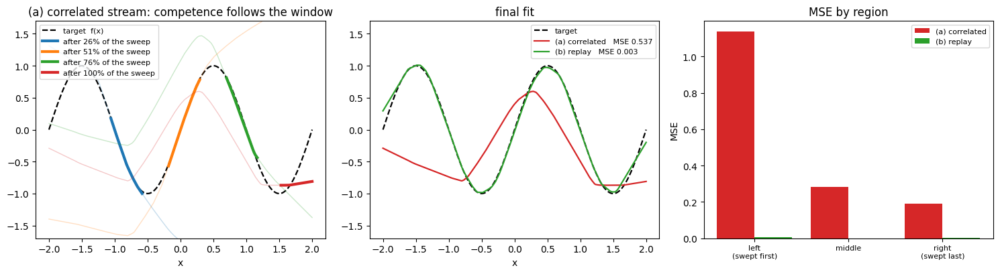

In [7]:
selected = [frames_correlated[int(f * (len(frames_correlated) - 1))]
            for f in (0.25, 0.5, 0.75, 1.0)]
mse_corr, thirds_corr = region_mse(net_correlated, x, y)
mse_replay, thirds_replay = region_mse(net_replay, x, y)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
SPAN = DOMAIN[1] - DOMAIN[0]

ax = axes[0]
ax.plot(x, y, "k--", lw=1.6, label="target  f(x)")
for k, (progress, pred) in enumerate(selected):
    color = f"C{k}"
    ax.plot(x, pred, lw=1.0, alpha=0.25, color=color)
    left = (1.0 - WINDOW_FRAC) * progress * SPAN + DOMAIN[0]
    in_window = (x >= left) & (x <= left + WINDOW_FRAC * SPAN)
    ax.plot(x[in_window], pred[in_window], lw=3.0, color=color,
            label=f"after {int(progress * 100)}% of the sweep")
ax.set_title("(a) correlated stream: competence follows the window")
ax.set_xlabel("x"); ax.set_ylim(-1.7, 1.7); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(x, y, "k--", lw=1.6, label="target")
ax.plot(x, frames_correlated[-1][1], color="C3", lw=1.6,
        label=f"(a) correlated   MSE {mse_corr:.3f}")
ax.plot(x, frames_replay[-1][1], color="C2", lw=1.6,
        label=f"(b) replay   MSE {mse_replay:.3f}")
ax.set_title("final fit")
ax.set_xlabel("x"); ax.set_ylim(-1.7, 1.7); ax.legend(fontsize=8)

ax = axes[2]
labels = ["left\n(swept first)", "middle", "right\n(swept last)"]
pos = np.arange(3)
ax.bar(pos - 0.2, thirds_corr, 0.4, color="C3", label="(a) correlated")
ax.bar(pos + 0.2, thirds_replay, 0.4, color="C2", label="(b) replay")
ax.set_xticks(pos); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("MSE"); ax.set_title("MSE by region")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

In [8]:
print("       (a) correlated stream          (b) replay buffer")
print("seed   full   left    mid  right      full   left    mid  right")
for seed in range(6):
    x, y = make_dataset()
    net_a, _ = train_correlated(make_network(seed), x, y, seed=seed)
    net_b, _ = train_replay(make_network(seed), x, y, seed=seed)
    fa, (la, ma, ra) = region_mse(net_a, x, y)
    fb, (lb, mb, rb) = region_mse(net_b, x, y)
    print(f"{seed:>3}   {fa:6.3f} {la:6.3f} {ma:6.3f} {ra:6.3f}    "
          f"{fb:6.3f} {lb:6.3f} {mb:6.3f} {rb:6.3f}")

       (a) correlated stream          (b) replay buffer
seed   full   left    mid  right      full   left    mid  right
  0    0.537  1.139  0.282  0.191     0.003  0.005  0.001  0.003
  1    0.421  0.896  0.257  0.109     0.007  0.015  0.002  0.005
  2    0.450  0.397  0.866  0.087     0.006  0.007  0.000  0.011
  3    0.282  0.539  0.146  0.161     0.005  0.008  0.001  0.006
  4    1.140  2.699  0.480  0.240     0.006  0.011  0.001  0.007
  5    0.340  0.380  0.536  0.104     0.008  0.001  0.002  0.021


In [9]:
SEED = 0
N_FRAMES = 60
x, y = make_dataset()
snapshot_every = max(1, N_UPDATES // N_FRAMES)

net_correlated, frames_correlated = train_correlated(
    make_network(SEED), x, y, seed=SEED, snapshot_every=snapshot_every)
net_replay, frames_replay = train_replay(
    make_network(SEED), x, y, seed=SEED, snapshot_every=snapshot_every)

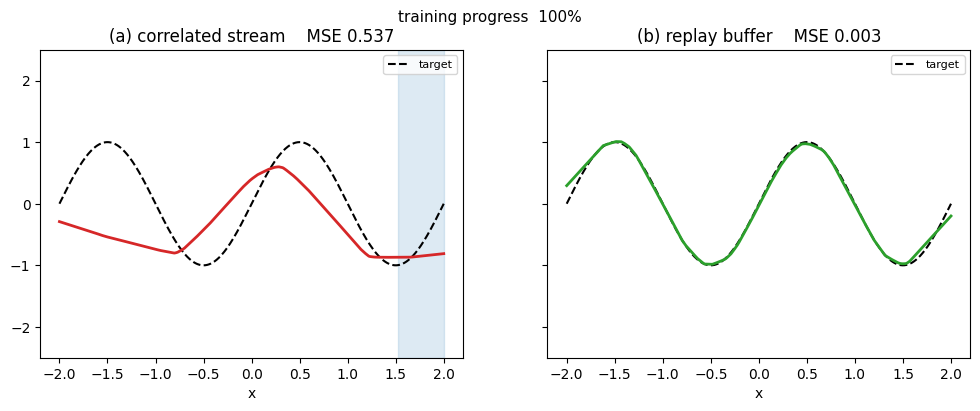

In [11]:
SPAN = DOMAIN[1] - DOMAIN[0]

for (progress, pred_a), (_, pred_b) in zip(frames_correlated, frames_replay):
    mse_a = float(np.mean((pred_a - y) ** 2))
    mse_b = float(np.mean((pred_b - y) ** 2))

    clear_output(wait=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    # (a) correlated -- shade the window the stream currently occupies
    ax = axes[0]
    left = (1.0 - WINDOW_FRAC) * progress * SPAN + DOMAIN[0]
    ax.axvspan(left, left + WINDOW_FRAC * SPAN, color="C0", alpha=0.15)
    ax.plot(x, y, "k--", lw=1.5, label="target")
    ax.plot(x, pred_a, color="C3", lw=2.0)
    ax.set_title(f"(a) correlated stream    MSE {mse_a:.3f}")
    ax.set_xlabel("x"); ax.legend(loc="upper right", fontsize=8)

    # (b) replay
    ax = axes[1]
    ax.plot(x, y, "k--", lw=1.5, label="target")
    ax.plot(x, pred_b, color="C2", lw=2.0)
    ax.set_title(f"(b) replay buffer    MSE {mse_b:.3f}")
    ax.set_xlabel("x"); ax.legend(loc="upper right", fontsize=8)

    axes[0].set_ylim(-2.5, 2.5)
    fig.suptitle(f"training progress  {int(progress * 100)}%", fontsize=11)
    plt.show()
    plt.close(fig)
    time.sleep(0.1)

The demonstration contained no reinforcement learning, but the situation it staged is exactly the one RL puts us in. An agent learns from a trajectory: the transitions it generates arrive in sequence, each about a state next to the last — a correlated stream, just like the swept points above. Neural Q-learning that updates on every transition as it is experienced is therefore the correlated regime, and it inherits that regime's failure.

The fix is the demo's other regime, carried into RL unchanged: rather than learn from the latest transition, the agent stores the transitions it experiences in a buffer and, to learn, draws samples from that buffer at random. Random sampling breaks the correlation just as it did here, and, as a side benefit, lets each transition be reused across many updates instead of being seen once and discarded. This is **experience replay**, the first of the two components that turn naive neural Q-learning into DQN — and we implement it for real in Part 2.

## The moving-target problem

Experience replay disposes of the first problem; the second is independent of it and would remain even if every update used perfectly decorrelated data. It concerns not the order of the updates but *what they aim at*. Q-learning has no labelled targets to regress onto — the environment never reveals the value of a state. The agent manufactures its own target by bootstrapping: it estimates the value of a state-action pair as the immediate reward plus the discounted value of the greedy action at the next state, $r + \gamma \max_{a'} \hat{q}(s', a', \mathbf{w})$. That target is assembled from the agent's own current estimate — and therefore from the very parameters $\mathbf{w}$ the update is about to change.

With a lookup table this does no harm. Updating $Q(s, a)$ writes to a single entry and leaves $Q(s', \cdot)$ untouched, so the target of every other transition holds still while we work — which is part of why tabular Q-learning is stable. A network shares its parameters across all inputs — the property that gave us representation learning in the first place — so one gradient step taken at $(s, a)$ moves $\hat{q}$ everywhere, $\hat{q}(s', \cdot, \mathbf{w})$ along with it. The target shifts the instant we step toward it. We are doing regression, but the labels are recomputed from the network being trained, fresh after every update: the estimate chases a target that moves away as it approaches.

Lecture 4 has been here before. Bootstrapping is one of the three legs of the deadly triad, and Baird's counterexample showed that this chase can do more than slow learning down — it can send the weights to infinity. But Lecture 4's purpose was *diagnostic*: to establish that the danger is real. Ours is *constructive*. Granting that the target moves, we ask what engineering keeps learning stable in spite of it.

We ask it, once again, in the abstract rather than on the microbe. The instability belongs to bootstrapping with a shared-parameter approximator, and it is seen most clearly when nothing else is in the way — no exploration schedule, no shifting policy, no reward structure to navigate. So the demonstration is a deliberately tiny Markov decision process, small enough that we can follow a single value estimate across the whole of training and see exactly what it does. The microbe returns in Part 2; here, as before, we want a clean instrument, not a realistic one.

Concretely, on this small MDP we run the bootstrapped update in two ways. In the first, the target is computed from the network as it currently stands, recomputed with the latest parameters at every step. In the second, the target is computed from a frozen copy of the network whose parameters are refreshed only at fixed intervals — the analogue of the mechanism we will call the **target network**. Everything else is held identical. We then follow the value estimate through training and ask, in each case, whether it settles or chases.

### Prediction on a short chain

To see the moving target on its own, we strip the problem down. Two simplifications: 

1. First, **we work with *prediction* rather than control**: we fix a policy and ask only to evaluate it — to estimate its value function — with no $\max$ over actions and no policy-improvement loop. The moving-target problem is a property of *bootstrapping* itself, and TD prediction bootstraps — building its target from its own current estimate of the next state — just as Q-learning does; dropping control removes the maximization and the exploration schedule without removing the thing we are here to study. (The short step back to Q-learning's $\max$-target we take later, once the fix is in hand.) 
2. Second, **fixing the policy collapses the MDP into a Markov reward process** — a chain of states with rewards and transitions but no actions left to choose — and the chain we use is deliberately tiny.

Its states are $n$ non-terminal states $0, 1, \dots, n-1$ together with a terminal state. The fixed policy advances deterministically, $s \to s+1$, until it steps from $n-1$ into the terminal state and the episode ends. Every transition yields reward $0$, except the last one, into the terminal state, which yields a reward $R$. With a discount factor $\gamma \in (0, 1)$ the value of every state is then known in closed form — it is the single future reward, discounted by the number of steps that separate the state from it:

$$V(s) = \gamma^{\,n-1-s}\, R, \qquad s = 0, 1, \dots, n-1.$$

The value decays geometrically, from $R$ at the last state to $\gamma^{n-1} R$ at the first. This is a deliberately benign problem: the value function is smooth, bounded, and easily representable, so there is no pathology hidden in the environment — any instability we observe will come from the learning procedure alone.

We approximate $V$ with a small neural network mapping the normalized state to a value — a shared-parameter approximator, the setting in which a moving target has teeth. Training is semi-gradient TD: for each transition $(s, r, s')$ the estimate $\hat{v}(s, \mathbf{w})$ is moved toward the bootstrapped target $r + \gamma\, \hat{v}(s', \mathbf{w})$. We run it in the two regimes named earlier. In the *live* regime that target is recomputed from the current network at every step. In the *frozen* regime it is computed from a separate copy of the network whose parameters are refreshed only once every $C$ steps. So that the comparison is about the target and nothing else, each update is full-batch — the gradient is taken over all of the chain's transitions at once — leaving no sampling noise and no ordering to confound the picture.

We then follow, across the whole of training, a single state far from the terminal: we plot its value estimate alongside the bootstrapped target that estimate is being pulled toward. Whether those two curves show an estimate settling onto a target that holds still, or chasing one that moves away as it approaches, is the whole question.

In [22]:
# --- chain (a Markov reward process) ---
N_STATES = 10        # non-terminal states 0 .. N_STATES-1, plus one terminal state
GAMMA = 0.9          # discount factor
REWARD = 1.0         # reward on the single transition into the terminal state

# --- network ---
HIDDEN_SIZE = 32
BATCH_SIZE = 1       # states updated per step (out of N_STATES); < N_STATES is what introduces the sampling noise

# --- training ---
LR = 0.05            # full-batch gradient-descent step size
N_STEPS = 2000       # total gradient-descent steps
SYNC_EVERY = 150     # frozen regime: refresh the target copy every SYNC_EVERY steps
SEED = 0

def chain_tensors(n_states=N_STATES, gamma=GAMMA, reward=REWARD):
    """Fixed ingredients of the chain: normalized state inputs, per-transition
    rewards, and the closed-form true value of each state."""
    states = np.arange(n_states, dtype=np.float32)
    x = (states / (n_states - 1)).reshape(-1, 1)               # normalized to [0, 1]
    rewards = np.zeros(n_states, dtype=np.float32)
    rewards[-1] = reward                                       # reward only into the terminal
    true_v = (reward * gamma ** (n_states - 1 - states)).astype(np.float32)
    return torch.from_numpy(x), torch.from_numpy(rewards), torch.from_numpy(true_v)

In [23]:
def make_value_network(seed=SEED, hidden_size=HIDDEN_SIZE):
    """A small MLP mapping a normalized scalar state to a value estimate."""
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(1, hidden_size), nn.ReLU(),
        nn.Linear(hidden_size, hidden_size), nn.ReLU(),
        nn.Linear(hidden_size, 1),
    )

def bootstrap_target(values, rewards, gamma):
    """Semi-gradient TD target for every state: r + gamma * v(next state).
    The successor of the last state is terminal, with value 0."""
    v_next = torch.cat([values[1:], values.new_zeros(1)])
    return rewards + gamma * v_next

def train_td(x, rewards, *, target_mode, lr=LR, n_steps=N_STEPS,
             sync_every=SYNC_EVERY, batch_size=BATCH_SIZE, gamma=GAMMA, seed=SEED):
    """Semi-gradient TD on the chain. Each step updates a random minibatch of
    states; the modest sampling noise this introduces is deliberate.

    target_mode='live'   : bootstrap target recomputed from the network each step.
    target_mode='frozen' : target from a copy refreshed every sync_every steps.

    Returns, for state 0, the value estimate and its bootstrap target at every step.
    """
    net = make_value_network(seed)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    target_net = make_value_network(seed) if target_mode == "frozen" else None
    rng = np.random.default_rng(seed)
    n = x.shape[0]

    estimate_0, target_0 = [], []
    for step in range(n_steps):
        values = net(x).squeeze(-1)

        if target_mode == "live":
            source = values.detach()
        elif target_mode == "frozen":
            if step % sync_every == 0:
                target_net.load_state_dict(net.state_dict())
            with torch.no_grad():
                source = target_net(x).squeeze(-1)
        else:
            raise ValueError("target_mode must be 'live' or 'frozen'")

        target = bootstrap_target(source, rewards, gamma)

        idx = torch.from_numpy(rng.choice(n, size=batch_size, replace=False))
        loss = ((values[idx] - target[idx]) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        estimate_0.append(values[0].item())
        target_0.append(target[0].item())

    return np.array(estimate_0), np.array(target_0)

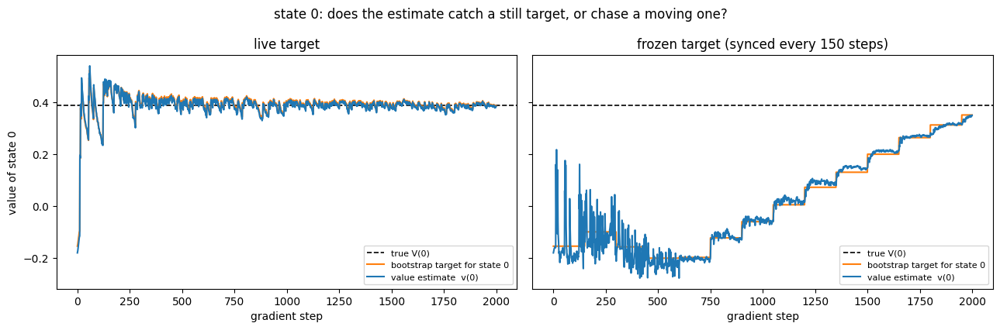

In [24]:
x, rewards, true_v = chain_tensors()

est_live, tgt_live = train_td(x, rewards, target_mode="live")
est_frozen, tgt_frozen = train_td(x, rewards, target_mode="frozen")

v0_true = true_v[0].item()
steps = np.arange(N_STEPS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, est, tgt, title in [
    (axes[0], est_live, tgt_live, "live target"),
    (axes[1], est_frozen, tgt_frozen, f"frozen target (synced every {SYNC_EVERY} steps)"),
]:
    ax.axhline(v0_true, color="k", ls="--", lw=1.2, label="true V(0)")
    ax.plot(steps, tgt, color="C1", lw=1.5, label="bootstrap target for state 0")
    ax.plot(steps, est, color="C0", lw=1.5, label="value estimate  v(0)")
    ax.set_title(title); ax.set_xlabel("gradient step")
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("value of state 0")
fig.suptitle("state 0: does the estimate catch a still target, or chase a moving one?")
fig.tight_layout()
plt.show()

The two runs converge to the same value, but the way they get there is not the same. With the live target, the estimate and the target it is pulled toward are never apart: every step recomputes the target, every step it shifts, and the estimate moves with it — the two settle onto the true value locked together. The estimate is always chasing; it is never handed a target that holds still. With the frozen target the picture is the staircase: the target is held fixed for a whole interval, so the estimate converges onto it as it would onto any fixed regression goal, and at each sync the target jumps to a better value. That staircase is fitted value iteration made visible — each of its steps is a single Bellman backup, regressed onto cleanly.

It is worth being precise about what this did and did not show. On this problem both regimes reach the true value; the live target's motion slowed nothing down and broke nothing. The difference is in the character of the process — chasing versus catching — not in success or failure. The reason is that the problem is benign: a fixed policy, on-policy evaluation, a value function the network can represent. With nothing else working against it, a target that merely slides is something semi-gradient TD can live with.

That qualifier — *with nothing else working against it* — is the whole point, because it is not the regime a real agent works in. DQN bootstraps with a deep nonlinear network, off-policy, from replayed rather than freshly sampled data: exactly the deadly triad of Lecture 4, the regime where bootstrapping can stop being benign. Control tightens it further — the bootstrapped target carries a $\max$ over actions, and that same $\max$ also defines the greedy policy, so a target that merely slid in prediction can, with a moving policy beneath it, begin to jump. None of this makes the moving target fatal on its own; it makes it one ingredient among several that a working method has to keep in hand.

The **frozen-copy regime above is what DQN calls a *target network*:** a periodically refreshed copy of the parameters the bootstrapped target is read from, held still long enough to be aimed at. With the replay buffer of the previous demonstration, it is the second of the two fixes these demonstrations have isolated. Part 2 assembles the full agent, both in place, and trains it on a realistic environment.

## Part 2 — The microbe's world

The closing of Part 1 promised a realistic environment; here it is, described before it is formalized. The setting is the one from the earlier lectures — a single microbe foraging across a shallow Petri dish for a patch of nutrient — but three changes separate it from the version you have seen, and together they make it a fitting test for an agent that learns its own representation rather than working from one supplied by hand. Read what follows as a situation, not yet a model: the next cell commits it to an MDP, and it is worth attempting that step yourself first.

1. **The first change is inertia.** The earlier microbe stepped — each action moved it directly to a neighbouring location. This one has mass, and it drifts. An action is no longer a step but a thrust: a push of fixed strength in one direction. A push does not place the microbe, it accelerates it; between thrusts the microbe coasts, slowed only gradually as the viscosity of the medium bleeds off its speed. A single thrust therefore keeps mattering long after it is delivered — the microbe carries the motion forward, gathers speed under repeated pushes, and cannot stop where it likes. To settle on the nutrient it has to ease off early and let the drag brake it, or thrust back against its own drift. Where the microbe should head depends on where it is and, just as much, on how it is already moving. Each foray begins from the same fixed point, the microbe at rest; whatever motion it then has is motion it has built for itself.

2. **What the microbe controls is modest.** Once per moment of time it fires a thrust in one of four directions — **up, down, left, or right** — and that is its whole repertoire: there is no brake, only thrusting and coasting. The dish is bounded by walls the microbe cannot cross; one that drifts into a wall is stopped against it, the motion carrying it in lost, though it stays free to thrust back into open water.

Two things shape what the microbe wants. 

1. The first is a **toxin diffused through the medium — not a wall and not lethal**: the microbe may swim anywhere, including straight through the worst of it, but the toxin harms it in proportion, and the denser the toxin where it finds itself, the more being there costs it. The toxin gathers around a handful of fixed sources and thins smoothly with distance, so the dish holds a continuous landscape of danger, with deep pools to be skirted and shallower water between them. 
2. The second is **the nutrient**: a single patch, fixed in place, that the microbe forages for. Reaching it is the whole point of an episode — the episode ends there, with a payoff far larger than anything else in the dish. Beneath both runs a steady pressure: merely staying alive and moving spends a little of the microbe's energy at every moment, so time itself is never free.

That is the environment entire: a dish, a drifting microbe, a landscape of toxin, a patch of nutrient, a metabolic clock. The exercise, before the next cell, is to cast this description as a Markov decision process — to fix its states, its actions, its transition rule, its rewards, its discount, the state each episode starts in, and the condition that ends one. Most of these the description hands you almost directly. One it does not: settling what the state must contain — what the microbe needs to carry forward so that its future turns on the present alone and not on its history — is the choice that rewards the most thought, and the inertia above is the reason it does. Hold that question; the formalization that follows is one answer to it.

### The Markov decision process

The description becomes a Markov decision process $(\mathcal{S}, \mathcal{A}, P, R, \gamma)$ once each part is pinned to a definition. Most parts follow the description almost mechanically. The state does not — and it is the one the inertia of the previous section was there to make you think about.

A microbe that drifts is not pinned down by its position. Two microbes at the same spot but moving differently have different futures — one coasting onto the nutrient, the other carried past it — so position is not a sufficient statistic, and a process whose state were position alone would not be Markov: the next position would depend on motion built up earlier, not on the current state. The state must carry that motion. It is the four-vector $s = (x, y, v_x, v_y)$ — position together with velocity. Position lies in the dish, $x \in [0, W]$ and $y \in [0, H]$ with $W = 12$ and $H = 6$. Velocity is bounded too, and not by stipulation: drag caps the speed any fixed thrust can build (the bound $v_{\max} = 1.25$ per axis is derived with the dynamics below). The state space is the bounded box $\mathcal{S} = [0, W] \times [0, H] \times [-v_{\max}, v_{\max}]^2 \subset \mathbb{R}^4$.

The actions are the four thrusts, $\mathcal{A} = \{\,\text{up}, \text{right}, \text{down}, \text{left}\,\}$ — each a push $u_a$ of one fixed magnitude in a cardinal direction. (The dish is drawn with $y$ increasing downward, image-style, so *up* is $-y$.) There is no brake among them: bringing the microbe to rest is something a policy arranges through thrust and drag, never something it commands directly.

The transition $P$ is deterministic. A step thrusts, lets drag act, and integrates the motion. With $\kappa$ the thrust magnitude and $c$ the drag fraction,
$$v_{t+1} = \operatorname{clip}\!\big((1 - c)\,v_t + \kappa\,u_{a_t},\; -v_{\max},\; v_{\max}\big), \qquad p_{t+1} = p_t + v_{t+1},$$
where $p = (x, y)$. A wall is inelastic: if $p_{t+1}$ leaves the dish on either axis, that coordinate is clamped to the boundary and the velocity component into the wall is set to zero. The velocity bound is a consequence of this rule, not an extra assumption — under a held thrust the recurrence $v \leftarrow (1-c)v + \kappa$ has fixed point $\kappa / c$ and approaches it from below, so no component ever exceeds $v_{\max} = \kappa/c$; with $\kappa = 0.25$ and $c = 0.2$, that is $1.25$.

The reward on a step gathers three terms — a metabolic cost paid always, a toxin penalty in proportion to where the microbe lands, and a bonus paid once, on reaching the goal:
$$r_t = \underbrace{-1}_{\text{metabolic}} \;-\; \underbrace{\lambda\,c(p_{t+1})}_{\text{toxin}} \;+\; \underbrace{100 \cdot \mathbb{1}[\,p_{t+1}\in\text{goal}\,]}_{\text{bonus}}, \qquad \lambda = 8.$$
The toxin concentration $c(p) \in [0, 1]$ is a fixed field — the superposition of $K = 3$ Gaussian sources, clipped at one:
$$c(p) = \min\!\Big(1,\; \textstyle\sum_{k=1}^{K} \exp\!\big(-\lVert p - p_k\rVert^2 / 2\sigma^2\big)\Big), \qquad \sigma = 1.1.$$
Note what is *not* in the state. The toxin needs no state variable of its own: the field is fixed and the microbe's position is already in the state, so $c$ is a function of $s$ already. The nutrient is the same — its location is fixed, so it belongs to the reward, not the state. Velocity had to be added because the dynamics demanded it; toxin and goal do not, because nothing about them varies independently of position.

The bonus is deliberately large. The cost a sensible route accumulates — metabolic plus the modest toxin of a well-chosen path — stays well under $100$, so reaching the nutrient is unambiguously the best outcome and a good policy never has reason to stall; this was the flaw in the earlier microbe's environment, whose goal paid only the step cost.

Three pieces close the tuple. The discount is $\gamma = 0.99$: the task is episodic, but holding $\gamma$ just below one keeps returns bounded and values on a moderate scale for the network, and alongside the metabolic cost it gently favours the shorter route. Every episode begins in the same state, $s_0 = (1, 3, 0, 0)$ — a fixed point at the left of the dish, the microbe at rest. An episode ends on exactly one condition: the microbe reaches the goal, the disc of radius $\rho = 0.6$ around a fixed centre $g$. The MDP carries no time limit of its own; a cap on episode length belongs to the training loop, and the environment never reports a truncation.

Two points of implementation are worth setting beside the formalization. Because a fast microbe can cross the entire goal disc inside one step, terminating on the landing point alone would sometimes miss it; the implementation instead tests whether the step's whole *segment* passes within $\rho$ of $g$. And the bounded state box is what makes observations safe to rescale: a thin wrapper maps every coordinate to $[0, 1]$ before the network reads it — the normalization motivated in Part 1 — so the agent sees a normalized state while the formalization above describes the raw one. The environment is implemented in `rlc/envs/realistic_microbe.py`; the cell below instantiates it and confirms its spaces.

In [25]:
from rlc.envs.realistic_microbe import RealisticMicrobeEnv

env = RealisticMicrobeEnv()

print("state space  :", env.observation_space)
print("action space :", env.action_space)
print("v_max        :", env.v_max)

obs, _ = env.reset(seed=0)
print("initial state:", obs)

state space  : Box([ 0.    0.   -1.25 -1.25], [12.    6.    1.25  1.25], (4,), float32)
action space : Discrete(4)
v_max        : 1.25
initial state: [1. 3. 0. 0.]


**The microbe movement**

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML
from rlc.envs.realistic_microbe import (RealisticMicrobeEnv,
                                        ACTION_RIGHT, ACTION_DOWN, ACTION_UP)

# A scripted run -- not a learned policy. Build rightward speed, then thrust
# down, then thrust up. The microbe keeps whatever motion it has already built;
# that carry-over, seen between the changes of thrust, is inertia.
plan = [ACTION_RIGHT] * 6 + [ACTION_DOWN] * 4 + [ACTION_UP] * 4
names = {ACTION_RIGHT: "RIGHT", ACTION_DOWN: "DOWN", ACTION_UP: "UP"}

env = RealisticMicrobeEnv(render_mode="rgb_array")
obs, _ = env.reset(seed=0)
frames = [env.render()]
trail = [obs[:2].copy()]
captions = ["start  --  microbe at rest"]
for a in plan:
    obs, *_ = env.step(a)
    frames.append(env.render())
    trail.append(obs[:2].copy())
    captions.append(f"thrust {names[a]}   --   velocity "
                    f"({obs[2]:+.2f}, {obs[3]:+.2f})")

ppu = frames[0].shape[1] / env.width          # pixels per dish unit
trail = np.array(trail) * ppu

fig, ax = plt.subplots(figsize=(7, 3.6))

def draw(i):
    ax.clear()
    ax.imshow(frames[i])
    ax.plot(trail[:i + 1, 0], trail[:i + 1, 1], "o-",
            color="white", lw=2.0, ms=3)
    ax.set_title(captions[i], fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=450)
plt.close(fig)
HTML(anim.to_jshtml())

**A random visit**

In [27]:
SEED = 42
MAX_STEPS = 200
STRIDE = 2          # env steps between captured animation frames

env = RealisticMicrobeEnv(render_mode="rgb_array", goal_radius=.6, toxic_sigma=1.1)
obs, _ = env.reset(seed=SEED)
rng = np.random.default_rng(SEED)

frames = [env.render()]
trail = [obs[:2].copy()]
captions = ["step 0   --   return 0"]
ep_return = 0.0
for t in range(1, MAX_STEPS + 1):
    obs, reward, terminated, *_ = env.step(int(rng.integers(env.action_space.n)))
    ep_return += reward
    if t % STRIDE == 0 or terminated:
        frames.append(env.render())
        trail.append(obs[:2].copy())
        tag = "reached the goal" if terminated else f"return {ep_return:+.0f}"
        captions.append(f"step {t}   --   {tag}")
    if terminated:
        break

ppu = frames[0].shape[1] / env.width
trail = np.array(trail) * ppu

fig, ax = plt.subplots(figsize=(7, 3.6))

def draw(i):
    ax.clear()
    ax.imshow(frames[i])
    ax.plot(trail[:i + 1, 0], trail[:i + 1, 1], "-",
            color="white", lw=1.2, alpha=0.7)
    ax.set_title(captions[i], fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=120)
plt.close(fig)
HTML(anim.to_jshtml())

## The Q-network

The environment is set; the agent is what remains, and at its centre is a function approximator for action-values — the same object as in Lectures 3 and 4, where $\hat{q}(s, a, \mathbf{w})$ stood in for a Q-table too large to hold. There it was linear, $\hat{q}(s, a, \mathbf{w}) = \mathbf{w}_a^{\top}\mathbf{x}(s)$, and it leaned on a feature map $\mathbf{x}(s)$ built by hand. For the microbe of Part 2 that hand step is where the difficulty would sit: the state is four-dimensional, and tiling four dimensions finely is the curse of dimensionality in plain sight; worse, inertia couples them — the worth of a position depends on the velocity carrying through it — so the features would have to be not merely many but nonlinearly entangled. The network removes the step. As Part 1 set out, its hidden layers *are* the feature map, learned by gradient descent rather than guessed in advance.

Concretely, the **Q-network is a small multilayer perceptron**. It takes the four-dimensional state (normalized to $[0,1]$ — the rescaling motivated in Part 1) and passes it through two hidden layers of 64 ReLU units to four output units: the action-values $\hat{q}(s, \text{up})$, $\hat{q}(s, \text{right})$, $\hat{q}(s, \text{down})$, $\hat{q}(s, \text{left})$. State in, the whole vector of action-values out.

Returning all four at once is a deliberate choice. One forward pass yields $\hat{q}(s, \cdot)$ for every action — exactly the quantity both halves of Q-learning need: the greedy action is the $\arg\max$ over that vector, the bootstrapped target its $\max$. The network is also small, a few thousand weights, and that is worth holding onto: the *deep* in deep Q-network names the learned representation, not the scale — two hidden layers of 64 units are enough. This network is only the core. The agent is built by wiring around it the two mechanisms of Part 1 — experience replay and a target network — which the next section takes up.

In [28]:
import torch
from rlc.agents.dqn import QNetwork

# 4 state features (x, y, vx, vy), 4 actions (the four thrusts)
q_net = QNetwork(n_state_features=4, n_actions=4, hidden_size=64)
print(q_net)

n_params = sum(p.numel() for p in q_net.parameters())
print(f"\nlearnable parameters: {n_params}")

# one forward pass: a normalized 4D state in, four action-values out
sample_state = torch.rand(1, 4)
print("\ninput shape :", tuple(sample_state.shape))
print("output shape:", tuple(q_net(sample_state).shape), " (one value per action)")

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)

learnable parameters: 4740

input shape : (1, 4)
output shape: (1, 4)  (one value per action)


## Assembling the DQN agent

Part 1 took the two failure modes of neural Q-learning apart one at a time. Correlation — consecutive, near-identical transitions dragging the network — was met with experience replay; the moving target — a bootstrap that shifts under the network as it learns — with a target network. Both were studied in the abstract, on deliberately small demos, their real implementations deferred. Those implementations are this section: the two fixes built around the Q-network of the previous section into a single agent.

**Experience replay is a buffer of past transitions** — the last fifty thousand, a sliding window. Every environment step, the new transition $(s, a, r, s', \text{done})$ is added. Crucially, the agent does not then learn from that transition: it learns from a minibatch of sixty-four transitions drawn uniformly at random from the whole buffer, a mix of old and recent, of states from all over the dish. Consecutive updates are decorrelated, exactly as the first demo asked, and each transition — instead of being used once and discarded — is revisited many times before it ages out.

**The bootstrapped target is computed from a second network**. The agent keeps a target network, a frozen copy of the Q-network, and the minibatch target $r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w}^-)$ reads its action-values from that copy, not from the network under training. Every five hundred updates the copy is refreshed to the current weights. Between refreshes the target holds still — the network is regressed toward a fixed objective, the staircase of the second demo rather than a target sliding out from under it.

Beneath the two fixes the update is the one from Lecture 4: a single semi-gradient step on the squared temporal-difference error, off-policy, the behaviour $\varepsilon$-greedy and decaying, Adam carrying the gradient. Replay and the target network change not the update itself but the data it draws and the target it chases — the standard two-part answer to the two problems Part 1 took apart. The agent exposes the same `select_action`, `update`, and `end_episode` interface as every agent in the course, so the training harness of the earlier lectures runs it unchanged. The next section does exactly that.

In [29]:
from rlc.agents.dqn import DQNAgent

agent = DQNAgent(n_state_features=4, n_actions=4, seed=0)

# the agent holds two copies of the network: the one it trains, and the target
same = all(torch.equal(p, t) for p, t in
           zip(agent.q_net.parameters(), agent.target_net.parameters()))
print("target network starts as a frozen copy of the Q-network:", same)

print("\nconfiguration")
print(f"  discount gamma            : {agent.gamma}")
print(f"  replay minibatch size     : {agent.batch_size}")
print(f"  learning starts after     : {agent.min_buffer_size} transitions")
print(f"  target sync every         : {agent.target_sync_every} updates")
print(f"  epsilon start/floor/decay : {agent.epsilon}, {agent.epsilon_min}, {agent.epsilon_decay}")

target network starts as a frozen copy of the Q-network: True

configuration
  discount gamma            : 0.99
  replay minibatch size     : 64
  learning starts after     : 1000 transitions
  target sync every         : 500 updates
  epsilon start/floor/decay : 1.0, 0.05, 0.995


## Training the agent

The agent is assembled; training is the same loop as every other agent in the course. For each of several random seeds a fresh DQN is trained on the microbe environment — wrapped in `NormalizeObs`, so the network sees coordinates rescaled to $[0,1]$ — for several hundred episodes, with the harness of Lectures 1-4. Several seeds, not one, because a single run can flatter or malign a method by luck; the honest picture is the spread across seeds. Two things are recorded as training proceeds: a periodic greedy-evaluation return, which is how well the policy actually performs, and the agent's own weight and gradient norms, which are how its training is holding up.

In [30]:
from rlc.envs.realistic_microbe import RealisticMicrobeEnv, NormalizeObs
from rlc.agents.dqn import DQNAgent
from rlc.utils.training import train

N_SEEDS = 2
N_EPISODES = 800
MAX_STEPS = 300
EVAL_EVERY = 25

TOXIC_SIGMA = 1.1

def make_env():
    return NormalizeObs(RealisticMicrobeEnv(toxic_sigma=TOXIC_SIGMA))

histories, agents = [], []
for seed in range(N_SEEDS):
    agent = DQNAgent(n_state_features=4, n_actions=4, seed=seed)
    history = train(
        agent, make_env(), N_EPISODES,
        max_steps_per_episode=MAX_STEPS,
        eval_every=EVAL_EVERY, eval_episodes=1,      # deterministic env: 1 is enough
        eval_env=make_env(), eval_max_steps=MAX_STEPS,
        seed=seed, progress=True,
    )
    histories.append(history)
    agents.append(agent)
    print(f"seed {seed}: final greedy return {history.eval_mean_returns[-1]:+.1f}")

Training:   0%|          | 0/800 [00:00<?, ?ep/s]

seed 0: final greedy return +73.6


Training:   0%|          | 0/800 [00:00<?, ?ep/s]

seed 1: final greedy return +72.5


### Diagnostics

Two figures read the run. The first is the learning curve — greedy-evaluation return against training episode, a faint line per seed with their mean in bold. The second is the stability check the multiple seeds were for: the norm of the network's weights and of its gradients, update by update.

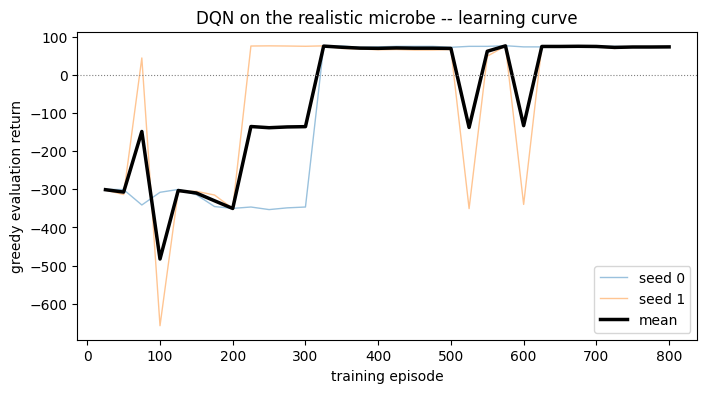

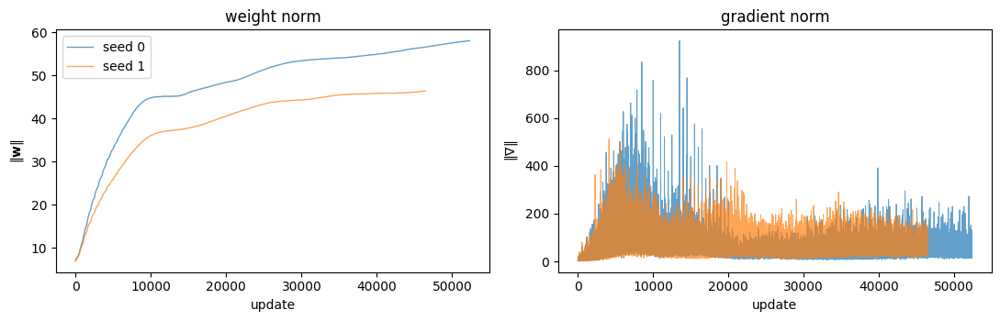

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# --- learning curve -------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
for seed, h in enumerate(histories):
    ax.plot(h.eval_episodes, h.eval_mean_returns, lw=1, alpha=0.45,
            label=f"seed {seed}")
mean_curve = np.mean([h.eval_mean_returns for h in histories], axis=0)
ax.plot(histories[0].eval_episodes, mean_curve, lw=2.5, color="black",
        label="mean")
ax.axhline(0.0, color="grey", lw=0.8, ls=":")
ax.set_xlabel("training episode")
ax.set_ylabel("greedy evaluation return")
ax.set_title("DQN on the realistic microbe -- learning curve")
ax.legend()
plt.show()

# --- stability diagnostics ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for seed, agent in enumerate(agents):
    axes[0].plot(agent.weight_norms, lw=1.0, alpha=0.7, label=f"seed {seed}")
    axes[1].plot(agent.grad_norms, lw=0.7, alpha=0.7)
axes[0].set_title("weight norm");   axes[0].set_xlabel("update")
axes[0].set_ylabel(r"$\|\mathbf{w}\|$"); axes[0].legend()
axes[1].set_title("gradient norm"); axes[1].set_xlabel("update")
axes[1].set_ylabel(r"$\|\nabla\|$")
fig.tight_layout()
plt.show()

In [32]:
best = int(np.argmax([h.eval_mean_returns[-1] for h in histories]))
trained = agents[best]
env = NormalizeObs(RealisticMicrobeEnv(render_mode="rgb_array", toxic_sigma=TOXIC_SIGMA))

obs, _ = env.reset(seed=0)
frames = [env.render()]
trail = [obs[:2].copy()]          # obs is normalized: position is obs[:2], in [0, 1]
captions = [f"seed {best}, greedy   --   step 0"]
ep_return = 0.0
for t in range(1, 301):
    obs, reward, terminated, *_ = env.step(trained.select_action(obs, greedy=True))
    ep_return += reward
    frames.append(env.render())
    trail.append(obs[:2].copy())
    tag = "reached the goal" if terminated else f"return {ep_return:+.0f}"
    captions.append(f"seed {best}, greedy   --   step {t}   --   {tag}")
    if terminated:
        break

frame_h, frame_w = frames[0].shape[:2]
trail = np.array(trail) * [frame_w, frame_h]      # normalized [0, 1] -> pixels

fig, ax = plt.subplots(figsize=(7, 3.6))

def draw(i):
    ax.clear()
    ax.imshow(frames[i])
    ax.plot(trail[:i + 1, 0], trail[:i + 1, 1], "o-",
            color="white", lw=2.0, ms=3)
    ax.set_title(captions[i], fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=200)
plt.close(fig)
HTML(anim.to_jshtml())